# Vinculum 03 · Point-in-time factor sorts

An end-to-end example of what the joined data is for: sort the 1,000 largest companies each
month on a fundamental signal, hold for a month, and compare the top and bottom quintiles.

- **Universe**: `ranks()` on each month end, top 1,000 by issuer market cap (survivorship free:
  companies that later failed or were acquired are in while they traded).
- **Signals**: from `fundamentals()` as known that day, plus 12-1 month price momentum as a
  non-fundamental benchmark.
- **Returns**: next month's total return (splits and dividends) from Massive's daily bars,
  by `security_id`, so renames don't break a series.

This is an illustration, not a backtester (equal weights, no costs, no risk model; that is
the planned `unimatrix-zero` package). The last section shows what look-ahead does to it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from massive_subspace_stream import Store
from subspace_probe import style, timed
from vinculum import Vinculum

style()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(170)
v = Vinculum()
massive = Store()
START = "2012-01-01"
END = v.status()["through"]
TOP = 1000

## 1 · Monthly total-return prices

The last adjusted close of each month per security, and the next month's return. A security's
last month (delisting, merger) still counts up to its last trade.

In [2]:
month = pl.col("date").dt.truncate("1mo").alias("month")
with timed("month-end total-return closes"):
    px = (massive.bars(None, start=START, end=END, adjust="all", lazy=True)
          .filter(pl.col("security_id").is_not_null())
          .group_by("security_id", month).agg(pl.col("close").sort_by("date").last())
          .collect())
idx = (pl.col("month").dt.year() * 12 + pl.col("month").dt.month()).alias("m")
px = px.with_columns(idx).sort("security_id", "m")
nxt = px.select("security_id", (pl.col("m") - 1).alias("m"), pl.col("close").alias("close_next"))
lag1 = px.select("security_id", (pl.col("m") + 1).alias("m"), pl.col("close").alias("close_1"))
lag12 = px.select("security_id", (pl.col("m") + 12).alias("m"), pl.col("close").alias("close_12"))
px = (px.join(nxt, on=["security_id", "m"], how="left").join(lag1, on=["security_id", "m"], how="left")
      .join(lag12, on=["security_id", "m"], how="left")
      .with_columns((pl.col("close_next") / pl.col("close") - 1).alias("ret_next"),
                    (pl.col("close_1") / pl.col("close_12") - 1).alias("momentum")))
print(f"{px.height:,} security-months, {px['security_id'].n_unique():,} securities")

month-end total-return closes: 2.73 s
1,723,327 security-months, 32,061 securities


## 2 · Universe and signals

Signals are oriented so that a higher value is expected to do better: low accruals, small size
and so on are negated.

In [3]:
items = ["revenue", "gross_profit", "net_income", "operating_cash_flow", "capex", "assets", "equity"]
with timed("fundamentals"):
    f = v.fundamentals(items, start=START)
dates = sorted(f["date"].unique().to_list())[:-1]  # the last month has no next-month return
with timed(f"ranks on {len(dates)} month ends"):
    uni = pl.concat([v.ranks(d).filter(pl.col("rank") <= TOP).select("date", "security_id") for d in dates])
ni, assets, equity = pl.col("net_income"), pl.col("assets"), pl.col("equity")
SIGNALS = {
    "book_to_market": pl.col("book_to_market"),
    "earnings_yield": pl.col("earnings_yield"),
    "sales_to_price": pl.col("sales_to_price"),
    "fcf_yield": pl.when(pl.col("currency") == "USD").then(
        (pl.col("operating_cash_flow") - pl.col("capex")) / pl.col("issuer_market_cap")),
    "gross_profitability": pl.when(assets > 0).then(pl.col("gross_profit") / assets),
    "roe": pl.when(equity > 0).then(ni / equity),
    "low_accruals": pl.when(assets > 0).then(-(ni - pl.col("operating_cash_flow")) / assets),
    "small_size": -pl.col("issuer_market_cap").log(),
    "momentum": pl.col("momentum"),
}
panel = (f.join(uni, on=["date", "security_id"]).with_columns(month)
         .join(px.select("security_id", "month", "ret_next", "momentum"), on=["security_id", "month"], how="left")
         .with_columns([e.alias(k) for k, e in SIGNALS.items()]))
print(f"{panel.height:,} company-months, {panel['date'].n_unique()} months, "
      f"{panel['ret_next'].is_not_null().mean():.1%} with a next-month return")
pl.DataFrame({"signal": list(SIGNALS), "coverage": [panel[s].is_not_null().mean() for s in SIGNALS]})

fundamentals: 10.15 s


ranks on 177 month ends: 0.77 s
177,000 company-months, 177 months, 100.0% with a next-month return


signal,coverage
str,f64
"""book_to_market""",0.928294
"""earnings_yield""",0.929023
"""sales_to_price""",0.892718
"""fcf_yield""",0.648203
"""gross_profitability""",0.430249
"""roe""",0.934028
"""low_accruals""",0.977373
"""small_size""",1.0
"""momentum""",0.912294


## 3 · Quintile portfolios

Each month, every signal splits the companies that have it into five equal groups (Q5 = highest
signal). Equal-weighted next-month returns per group:

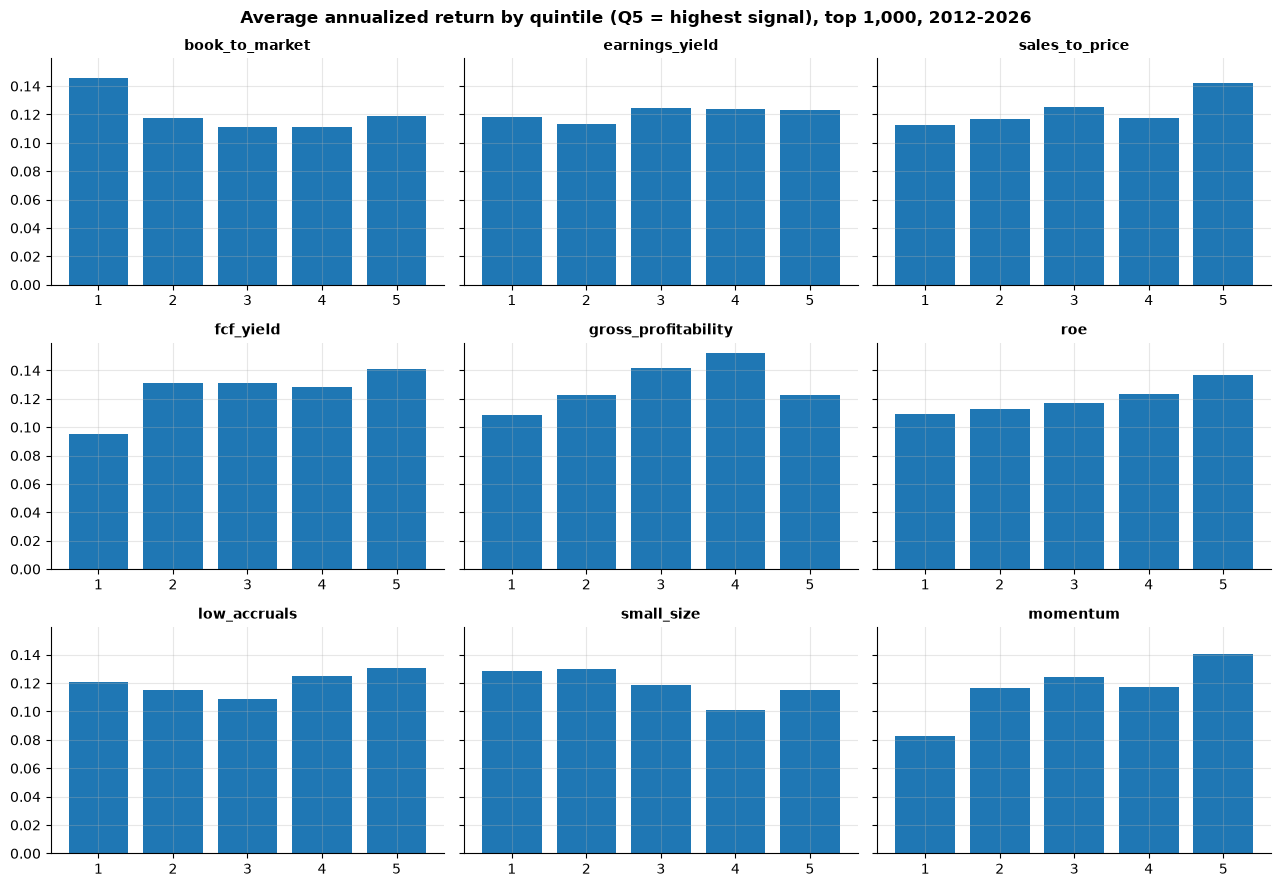

In [4]:
def quintile(s: str) -> pl.Expr:
    r = pl.col(s).rank("ordinal").over("date")
    return ((r - 1) * 5 / pl.col(s).count().over("date")).floor().cast(pl.Int8) + 1


ret = pl.col("ret_next").clip(-0.99, 3)  # guard against bad prints; changes few months
rows = []
for s in SIGNALS:
    q = (panel.filter(pl.col(s).is_not_null() & pl.col("ret_next").is_not_null())
         .with_columns(quintile(s).alias("q")).group_by("date", "q").agg(ret.mean().alias("ret")))
    rows.append(q.with_columns(pl.lit(s).alias("signal")))
quint = pl.concat(rows)
means = quint.group_by("signal", "q").agg((pl.col("ret").mean() * 12).alias("annual")).sort("q")
fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharey=True)
for ax, s in zip(axes.flat, SIGNALS, strict=True):
    m = means.filter(pl.col("signal") == s)
    ax.bar(m["q"], m["annual"])
    ax.set_title(s, fontsize=10)
    ax.set_xticks([1, 2, 3, 4, 5])
fig.suptitle("Average annualized return by quintile (Q5 = highest signal), top 1,000, 2012-2026",
             fontweight="bold")
fig.tight_layout()
plt.show()

In [5]:
ls = (quint.pivot(on="q", index=["date", "signal"], values="ret")
      .with_columns((pl.col("5") - pl.col("1")).alias("long_short")).sort("date"))


def stats(df: pl.DataFrame, col: str) -> pl.DataFrame:
    return (df.group_by("signal").agg(
        pl.len().alias("months"),
        (pl.col(col).mean() * 12).alias("annual_return"),
        (pl.col(col).std() * np.sqrt(12)).alias("annual_vol"),
        (pl.col(col).mean() / pl.col(col).std() * np.sqrt(12)).alias("sharpe"),
        (pl.col(col).mean() / pl.col(col).std() * pl.len().sqrt()).alias("t_stat"),
        (pl.col(col) > 0).mean().alias("hit_rate"))
        .sort("sharpe", descending=True).with_columns(pl.col(pl.Float64).round(3)))


stats(ls, "long_short")

signal,months,annual_return,annual_vol,sharpe,t_stat,hit_rate
str,u32,f64,f64,f64,f64,f64
"""momentum""",165,0.058,0.161,0.359,1.331,0.558
"""fcf_yield""",177,0.045,0.131,0.345,1.326,0.542
"""roe""",177,0.027,0.093,0.293,1.124,0.559
"""sales_to_price""",177,0.03,0.139,0.216,0.83,0.48
"""gross_profitability""",177,0.014,0.101,0.143,0.55,0.503
"""low_accruals""",177,0.01,0.07,0.142,0.545,0.525
"""earnings_yield""",177,0.005,0.131,0.039,0.151,0.492
"""small_size""",177,-0.013,0.072,-0.182,-0.7,0.492
"""book_to_market""",177,-0.027,0.133,-0.202,-0.774,0.463


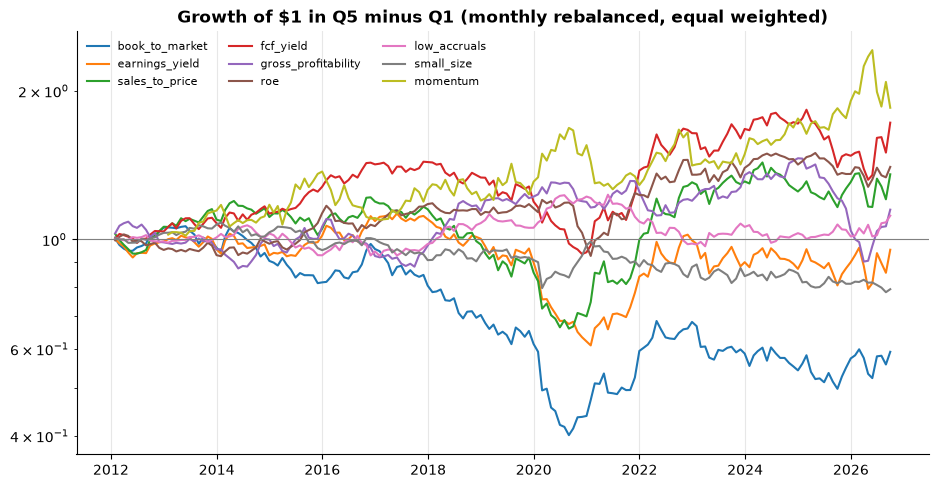

In [6]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for s in SIGNALS:
    g = ls.filter(pl.col("signal") == s)
    ax.plot(g["date"], (1 + g["long_short"]).log().cum_sum().exp(), label=s)
ax.axhline(1, color="grey", lw=0.8)
ax.set_yscale("log")
ax.set_title("Growth of $1 in Q5 minus Q1 (monthly rebalanced, equal weighted)")
ax.legend(fontsize=8, ncol=3)
plt.show()

In [7]:
(ls.group_by(pl.col("date").dt.year().alias("year"), "signal").agg(((1 + pl.col("long_short")).product() - 1).alias("r"))
 .pivot(on="signal", index="year", values="r").sort("year").select("year", *SIGNALS)
 .with_columns(pl.exclude("year").round(3)))

year,book_to_market,earnings_yield,sales_to_price,fcf_yield,gross_profitability,roe,low_accruals,small_size,momentum
i32,f64,f64,f64,f64,f64,f64,f64,f64,f64
2012,0.056,-0.01,0.061,0.037,-0.014,-0.048,-0.01,0.031,null
2013,-0.089,-0.036,0.034,0.039,-0.032,-0.024,0.019,0.04,0.144
2014,-0.06,-0.028,0.012,0.045,0.047,0.055,0.019,-0.036,0.027
2015,-0.095,0.097,-0.053,0.134,0.062,0.154,-0.097,-0.08,0.167
2016,0.168,0.07,0.135,0.11,-0.128,-0.059,0.018,0.052,-0.195
2017,-0.157,0.009,-0.035,0.011,0.05,0.108,0.035,-0.093,0.141
2018,-0.128,-0.087,-0.152,-0.069,0.176,-0.049,0.102,0.028,-0.049
2019,-0.127,-0.105,-0.123,-0.106,0.069,0.031,-0.021,-0.027,0.092
2020,-0.285,-0.308,-0.185,-0.21,-0.024,-0.16,0.157,0.071,0.186


The results line up with what is known about the period, which is a useful check of the
plumbing:

- **Book-to-market value lost money** in large caps: cheap stocks lagged expensive ones in most
  years from 2013 to 2020 (−28% in 2020 alone), then rebounded in 2021-22 (+35% in 2021).
- **Cash-flow value and profitability held up better**: free-cash-flow yield and ROE have the
  highest Sharpe ratios among the fundamental signals.
- **Momentum** had the best Sharpe ratio, but with crashes at the turns (2016, and 2021 when
  value came back).
- **Small size** lost: within the top 1,000, the largest companies beat the smaller ones.

None of the long-short spreads is significant at conventional levels (|t| < 2) over 14 years:
a reminder of how noisy single-factor returns are.

## 4 · Information coefficients

The monthly rank correlation between each signal and next month's return: a finer measure than
quintile spreads, using every stock.

In [8]:
ic = pl.concat([
    panel.filter(pl.col(s).is_not_null() & pl.col("ret_next").is_not_null())
    .group_by("date").agg(pl.corr(s, "ret_next", method="spearman").alias("ic"))
    .with_columns(pl.lit(s).alias("signal")) for s in SIGNALS])
(ic.group_by("signal").agg(pl.col("ic").mean().alias("mean_ic"), pl.col("ic").std().alias("ic_std"),
                           (pl.col("ic").mean() / pl.col("ic").std() * pl.len().sqrt()).alias("t_stat"),
                           (pl.col("ic") > 0).mean().alias("positive_months"))
 .sort("mean_ic", descending=True).with_columns(pl.col(pl.Float64).round(3)))

signal,mean_ic,ic_std,t_stat,positive_months
str,f64,f64,f64,f64
"""fcf_yield""",0.021,0.134,2.06,0.554
"""roe""",0.018,0.089,2.717,0.599
"""earnings_yield""",0.014,0.138,1.305,0.537
"""sales_to_price""",0.013,0.147,1.168,0.514
"""momentum""",0.011,0.175,0.81,0.539
"""gross_profitability""",0.01,0.109,1.261,0.542
"""low_accruals""",-0.002,0.076,-0.423,0.508
"""book_to_market""",-0.006,0.149,-0.568,0.452
"""small_size""",-0.013,0.087,-2.03,0.452


## 5 · What look-ahead does

The same earnings-yield sort, but using the TTM net income that will be known **three months
later** against today's price, as a study does when it dates fundamentals by period end or
uses restated data. The "signal" now knows the next earnings release.

In [9]:
f_ni = f.select("security_id", pl.col("date").dt.truncate("1mo").alias("month"), "net_income").with_columns(
    pl.col("month").dt.offset_by("-3mo").alias("month")).rename({"net_income": "net_income_in_3m"})
peek = (panel.join(f_ni, on=["security_id", "month"], how="left")
        .with_columns(pl.when(pl.col("currency") == "USD")
                      .then(pl.col("net_income_in_3m") / pl.col("issuer_market_cap")).alias("ey_peek")))
out = []
for name, col in [("earnings_yield (point in time)", "earnings_yield"), ("earnings_yield (3 months ahead)", "ey_peek")]:
    d = peek.filter(pl.col(col).is_not_null() & pl.col("ret_next").is_not_null()).with_columns(quintile(col).alias("q"))
    q = d.group_by("date", "q").agg(ret.mean().alias("ret")).pivot(on="q", index="date", values="ret")
    ics = d.group_by("date").agg(pl.corr(col, "ret_next", method="spearman").alias("ic"))
    out.append(q.select((pl.col("5") - pl.col("1")).alias("long_short")).with_columns(pl.lit(name).alias("signal"))
               .pipe(stats, "long_short").with_columns(pl.lit(ics["ic"].mean()).round(4).alias("mean_ic")))
pl.concat(out)

signal,months,annual_return,annual_vol,sharpe,t_stat,hit_rate,mean_ic
str,u32,f64,f64,f64,f64,f64,f64
"""earnings_yield (point in time)""",177,0.005,0.131,0.039,0.151,0.492,0.0135
"""earnings_yield (3 months ahead…",175,0.069,0.129,0.539,2.059,0.537,0.0337


Knowing next quarter's earnings is worth a lot. From the same data, the look-ahead version
turns a flat signal (Sharpe 0.04) into a seemingly strong one (Sharpe 0.54, t above 2), and
the information coefficient more than doubles. Point-in-time dating (each value
usable from the day after its filing, first-filed values only) is what keeps a backtest honest.

## 6 · Caveats

- **Equal weights, monthly rebalancing, no costs.** Small companies within the top 1,000 drive
  equal-weighted results; turnover costs would eat into momentum most.
- **Delisting returns are partial**: the last month counts up to the last trade, but a stock
  that stops trading after a collapse loses less here than a holder would have.
- **Ratios use today's market cap** (refreshed monthly), not the June/December lag of the
  academic definitions; signals are not industry-neutral, so value is partly a sector bet.
- **One period, one universe.** 2012-2026 large and mid caps; nothing here is a claim about
  other periods or small caps.